# Chapter 9: Converting Words to Numbers with Word Embedding!!!

In [1]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
import matplotlib.pyplot as plt

In [2]:
sentences = ['Troll is great!', 'Gymkata is great!']
cleaned_sentences = [sentence.replace('!', '').lower() for sentence in sentences]
unique_words = list(set(' '.join(cleaned_sentences).split(' ')))
unique_words_nr = len(unique_words)
unique_words_mapping = {}

for unique_word_index, unique_word in enumerate(unique_words):
    unique_words_mapping[unique_word] = unique_word_index

print(unique_words)

['troll', 'great', 'is', 'gymkata']


In [3]:
X = []
y = []

for sentence in cleaned_sentences:
    words = sentence.split(' ')
    words_nr = len(words)
    
    for word_index_in_sentence in range(words_nr - 1):
        current_word = words[word_index_in_sentence]
        next_word = words[word_index_in_sentence + 1]

        X_local = [0] * unique_words_nr
        X_local[unique_words_mapping[current_word]] = 1

        y_local = [0] * unique_words_nr
        y_local[unique_words_mapping[next_word]] = 1
        
        X.append(X_local)
        y.append(y_local)
        
print(X)
print(y)

[[1, 0, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1], [0, 0, 1, 0]]
[[0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0]]


In [4]:
X_tensor = torch.tensor(X).float()
y_tensor = torch.tensor(y).float()

dataset = TensorDataset(X_tensor, y_tensor)
data_loader = DataLoader(dataset, batch_size=dataset.tensors[0].shape[0], shuffle=True)

In [5]:
class EmbedNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.input = nn.Linear(unique_words_nr, 2)
        self.output = nn.Linear(2, unique_words_nr)
        
    def forward(self, x):
        embeddings = self.input(x)
        
        return self.output(embeddings), embeddings
    
embed_net = EmbedNet()
optimizer = torch.optim.Adam(embed_net.parameters())
loss_fun = nn.CrossEntropyLoss()

In [6]:
losses = []
accuracies = []

embed_net.train()

for epoch in range(5000):
    for X_local, y_local in data_loader:
        y_pred, _ = embed_net(X_local)
        loss = loss_fun(y_pred, y_local)
        
        losses.append(loss.detach().item())
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        y_local_max = torch.argmax(y_local, dim=1)
        y_pred_max = torch.argmax(y_pred, dim=1)

        correct_y = y_local_max == y_pred_max
        
        accuracies.append(torch.mean(correct_y.float()).item())

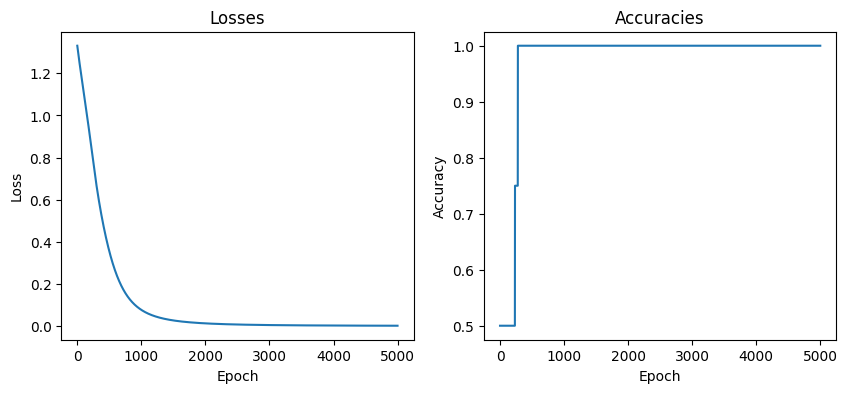

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(losses)
ax[0].set_title('Losses')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')

ax[1].plot(accuracies)
ax[1].set_title('Accuracies')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')

plt.show()

In [8]:
embed_net.eval()

word_embeddings = []

for unique_word in unique_words:
    word_one_hot_encoding = [0] * unique_words_nr
    word_one_hot_encoding[unique_words_mapping[unique_word]] = 1
    word_one_hot_encoding_tensor = torch.tensor([word_one_hot_encoding]).float()
    _, word_embedding = embed_net(word_one_hot_encoding_tensor)

    word_embeddings.append((unique_word, word_embedding.detach()[0]))

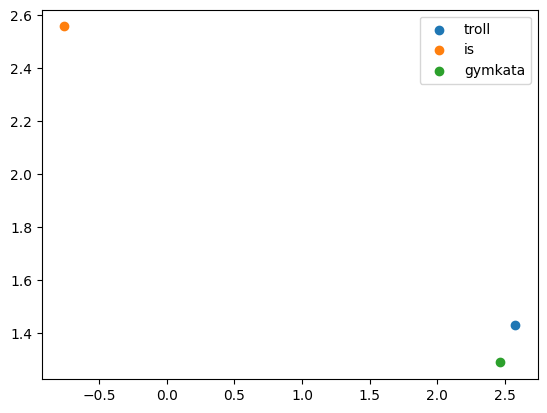

In [9]:
for word, embedding in word_embeddings:
    if word != 'great':
        plt.scatter(embedding[0], embedding[1], label=word)
  
plt.legend()
plt.show()